# Análisis Exploratorio de Datos (EDA): Consumo Energético de Electrodomésticos

**Enfoque:** Modelamiento explicativo sobre los factores ambientales y temporales que determinan el consumo (`Appliances`).

## 1. Carga de datos y partición temporal

Dado que los registros corresponden a una serie temporal cada 10 minutos (entre el 11 de enero al 27 de mayo de 2016) y el objetivo es validar respetando el orden cronológico, realizamos primero una partición **80% entrenamiento / 20% validación** antes de explorar las variables. 
- Todo el EDA se ejecuta estrictamente sobre el conjunto de entrenamiento para evitar fuga de información (*data leakage*) hacia nuestras decisiones de modelamiento.

In [1]:
# Cargar librerías
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
  library(e1071)
  library(rio)
})

# Opciones para gráficos
options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 150)
theme_set(theme_minimal(base_size = 12))

# Cargar el dataset
df <- import("../Parte 1 - j-santaana/Base de datos procesada/energydata_limpio.csv") %>%
  mutate(date = as.POSIXct(date, tz = "UTC")) %>%
  arrange(date)

head(df)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,⋯,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
,<dttm>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2016-01-11 17:00:00,60,30,19.89,47.59667,19.2,44.79000,19.79,44.73000,19.00000,⋯,18.2,48.90000,17.03333,45.53,6.600000,733.5,92,7.000000,63.00000,5.3
2,2016-01-11 17:10:00,60,30,19.89,46.69333,19.2,44.72250,19.79,44.79000,19.00000,⋯,18.2,48.86333,17.06667,45.56,6.483333,733.6,92,6.666667,59.16667,5.2
3,2016-01-11 17:20:00,50,30,19.89,46.30000,19.2,44.62667,19.79,44.93333,18.92667,⋯,18.2,48.73000,17.00000,45.50,6.366667,733.7,92,6.333333,55.33333,5.1
4,2016-01-11 17:30:00,50,40,19.89,46.06667,19.2,44.59000,19.79,45.00000,18.89000,⋯,18.1,48.59000,17.00000,45.40,6.250000,733.8,92,6.000000,51.50000,5.0
5,2016-01-11 17:40:00,60,40,19.89,46.33333,19.2,44.53000,19.79,45.00000,18.89000,⋯,18.1,48.59000,17.00000,45.40,6.133333,733.9,92,5.666667,47.66667,4.9
6,2016-01-11 17:50:00,50,40,19.89,46.02667,19.2,44.50000,19.79,44.93333,18.89000,⋯,18.1,48.59000,17.00000,45.29,6.016667,734.0,92,5.333333,43.83333,4.8


In [2]:
# 2. Corte temporal estricto: 80% inicial para entrenamiento/EDA
n_total <- nrow(df)
corte_idx <- floor(0.80 * n_total)

train_df <- df %>% slice(1:corte_idx)
test_df  <- df %>% slice((corte_idx + 1):n_total)

cat(sprintf("Total registros: %d | Entrenamiento (80%%): %d | Validación (20%%): %d\n",
            n_total, nrow(train_df), nrow(test_df)))
cat(sprintf("Período de entrenamiento: %s hasta %s\n",
            min(train_df$date), max(train_df$date)))

Total registros: 19735 | Entrenamiento (80%): 15788 | Validación (20%): 3947
Período de entrenamiento: 2016-01-11 17:00:00 hasta 2016-04-30 08:10:00


## 2. Distribución del consumo energético (`Appliances`)

El consumo de electrodomésticos en una vivienda suele separarse en un **consumo base** (refrigeración, equipos en espera) interrumpido por **picos intensos y breves** cuando operan aparatos de alta potencia (lavadora, secadora, horno). 

Se calculan medidas de tendencia central, dispersión y forma para cuantificar esta asimetría.

In [3]:
resumen_consumo <- train_df %>%
  summarise(
    Observaciones = n(),
    Minimo        = min(Appliances),
    Q1_P25        = quantile(Appliances, 0.25),
    Mediana       = median(Appliances),
    Media         = mean(Appliances),
    Q3_P75        = quantile(Appliances, 0.75),
    P95           = quantile(Appliances, 0.95),
    P99           = quantile(Appliances, 0.99),
    Maximo        = max(Appliances),
    Desv_Est      = sd(Appliances),
    RIC           = IQR(Appliances),
    Asimetria     = skewness(Appliances)
  )

# Mostrar en formato vertical para lectura limpia
resumen_consumo %>%
  pivot_longer(everything(), names_to = "Estadístico", values_to = "Valor") %>%
  mutate(Valor = round(Valor, 2))

Estadístico,Valor
<chr>,<dbl>
Observaciones,15788.00
Minimo,10.00
Q1_P25,50.00
Mediana,60.00
Media,98.02
Q3_P75,100.00
P95,340.00
P99,581.30
Maximo,1080.00


*Observación*: Las observaciones son estríctamente mayores a 0, por lo que aplicar una tranformación logarítmica es posible.

### Visualización de la distribución

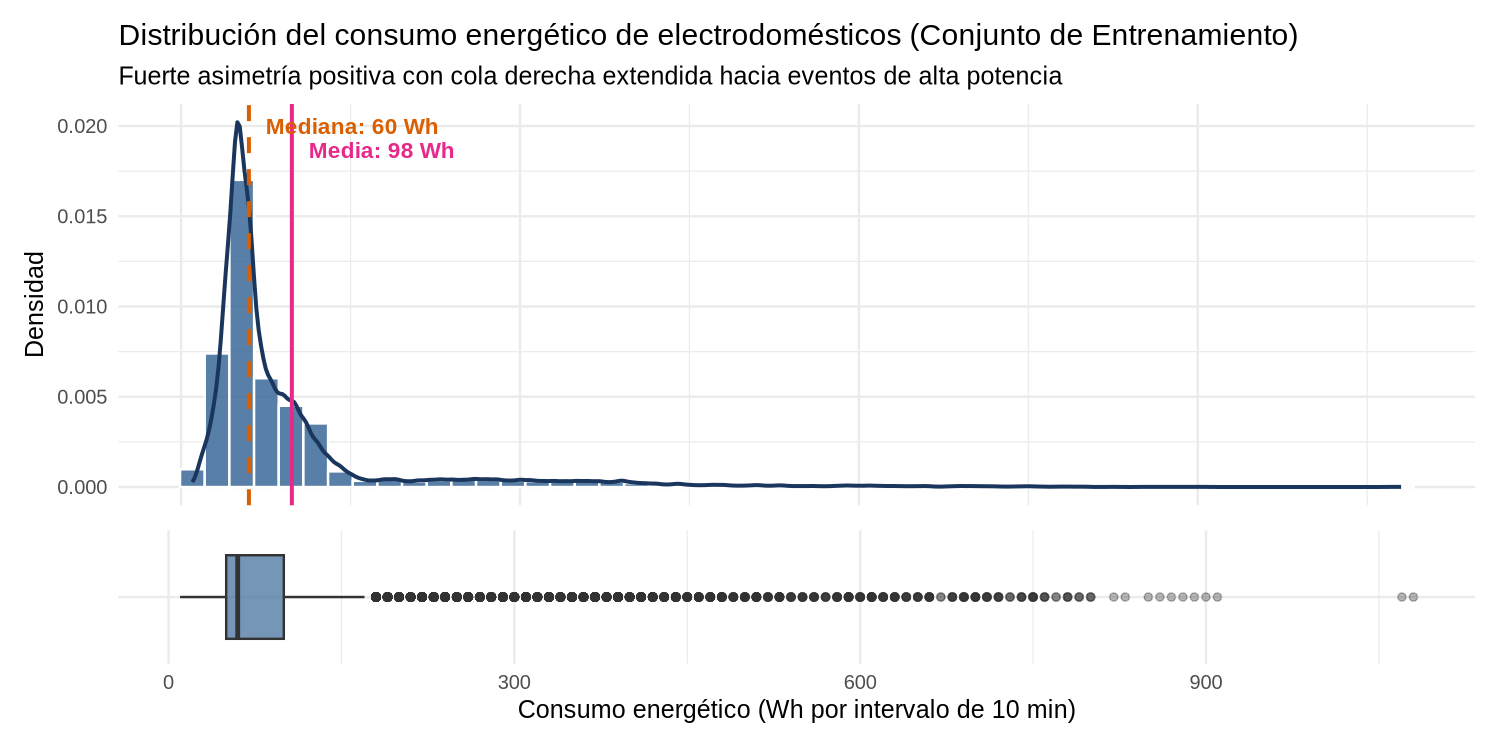

In [4]:
media_val   <- mean(train_df$Appliances)
mediana_val <- median(train_df$Appliances)

p_hist <- ggplot(train_df, aes(x = Appliances)) +
  geom_histogram(aes(y = after_stat(density)), bins = 50,
                 fill = "#3B6998", color = "white", alpha = 0.85) +
  geom_density(color = "#1B365D", linewidth = 0.9) +
  geom_vline(xintercept = mediana_val, color = "#D95F02", linetype = "dashed", linewidth = 0.9) +
  geom_vline(xintercept = media_val, color = "#E7298A", linetype = "solid", linewidth = 0.9) +
  annotate("text", x = mediana_val + 15, y = Inf, label = paste0("Mediana: ", round(mediana_val, 1), " Wh"),
           vjust = 2, hjust = 0, color = "#D95F02", fontface = "bold", size = 3.8) +
  annotate("text", x = media_val + 15, y = Inf, label = paste0("Media: ", round(media_val, 1), " Wh"),
           vjust = 3.6, hjust = 0, color = "#E7298A", fontface = "bold", size = 3.8) +
  labs(
    title = "Distribución del consumo energético de electrodomésticos (Conjunto de Entrenamiento)",
    subtitle = "Fuerte asimetría positiva con cola derecha extendida hacia eventos de alta potencia",
    x = NULL,
    y = "Densidad"
  ) +
  theme(axis.text.x = element_blank(), axis.ticks.x = element_blank())

p_box <- ggplot(train_df, aes(x = Appliances, y = "")) +
  geom_boxplot(fill = "#3B6998", alpha = 0.7, outlier.alpha = 0.35, outlier.size = 1.5) +
  labs(
    x = "Consumo energético (Wh por intervalo de 10 min)",
    y = NULL
  )

# Combinar verticalmente dando 75% de altura al histograma y 25% al boxplot
p_hist / p_box + plot_layout(heights = c(3, 1))

*Observaciones:*
- La `Mediana` es 60 Wh, el consumo base de electrodomésticos en espera suele estar entre 5-15 Wh lo que está en línea con el primer cuartil (`Minimo` a `Q1_P25`)
- La `Media` es 98 Wh, esta se ve desplazada respecto a la mediana por los valores extremos presentes en el cuarto cuartil (`Q3_P75` a `Máximo`)
- Los outliers vistos en el boxplot son electrodomésticos de alto consumo.
- Los datos de alto consumo energéticos se concentran en la cola derecha del 5%.
- El alto coeficiente de `Asimetría` de 3.32 nos da otra base fuerte para justificar la tranformación logarítmica y estabilizar la varianza (`Desv_Est`)

## 3. Evaluación de la transformación logarítmica de la respuesta

Comparamos ambas escalas mediante:
1. **Estadísticos de forma y prueba de Jarque-Bera:** Evaluamos la reducción en asimetría y curtosis respecto a una distribución normal teórica ($\text{asimetría} = 0$, $\text{curtosis en exceso} = 0$).
2. **Gráficos de densidad y Q-Q (*Quantile-Quantile*):** Inspeccionamos el ajuste de los cuantiles empíricos a la recta normal.

In [5]:
# Crear variable transformada y extraer hora para probar estabilidad de varianza
train_df <- train_df %>%
  mutate(
    log_Appliances = log(Appliances),
    hora = factor(lubridate::hour(date))
  )

# Función auxiliar para calcular estadístico y p-valor de Jarque-Bera sin librerías extra
calc_jb <- function(x) {
  n <- length(x)
  s <- e1071::skewness(x)
  k <- e1071::kurtosis(x) # curtosis en exceso
  jb_stat <- (n / 6) * (s^2 + (k^2) / 4)
  p_val <- pchisq(jb_stat, df = 2, lower.tail = FALSE)
  c(JB = jb_stat, p_value = p_val)
}

jb_orig <- calc_jb(train_df$Appliances)
jb_log  <- calc_jb(train_df$log_Appliances)

comparacion_trans <- tibble(
  Metrica = c("Media", "Mediana", "Desviación Estándar", "RIC", 
              "Asimetría (Skewness)", "Curtosis en exceso", 
              "Estadístico Jarque-Bera", "p-valor Jarque-Bera"),
  Escala_Original_Wh = c(
    mean(train_df$Appliances), median(train_df$Appliances),
    sd(train_df$Appliances), IQR(train_df$Appliances),
    skewness(train_df$Appliances), kurtosis(train_df$Appliances),
    jb_orig["JB"], jb_orig["p_value"]
  ),
  Escala_Logaritmica = c(
    mean(train_df$log_Appliances), median(train_df$log_Appliances),
    sd(train_df$log_Appliances), IQR(train_df$log_Appliances),
    skewness(train_df$log_Appliances), kurtosis(train_df$log_Appliances),
    jb_log["JB"], jb_log["p_value"]
  )
)

comparacion_trans %>%
  mutate(across(where(is.numeric), ~ round(.x, 4)))

Metrica,Escala_Original_Wh,Escala_Logaritmica
<chr>,<dbl>,<dbl>
Media,98.0244,4.2910
Mediana,60.0000,4.0943
Desviación Estándar,105.1983,0.6767
RIC,50.0000,0.6931
Asimetría (Skewness),3.3217,1.1271
Curtosis en exceso,13.1135,1.3728
Estadístico Jarque-Bera,142156.1894,4582.3265
p-valor Jarque-Bera,0.0000,0.0000


*Observaciones:*
- `Curtosis en exceso`: Hay una reducción del 90% en la escala logarítmica. La distribución pasa de una con datos consentrados en la media y de colas pesadas (gran cantidad de outliers) a una distribución más cercana a la normal.
- `Jarque-Bera`: Si bien la distribución se acerca más a la normal, la prueba de Jarque-Bera (ideal cuando se trabaja con muestras grandes) rechaza la normalidad debido a desviaciones generadas por la mezcla de regímenes horarios. La distribución sigue siendo asimétrica.

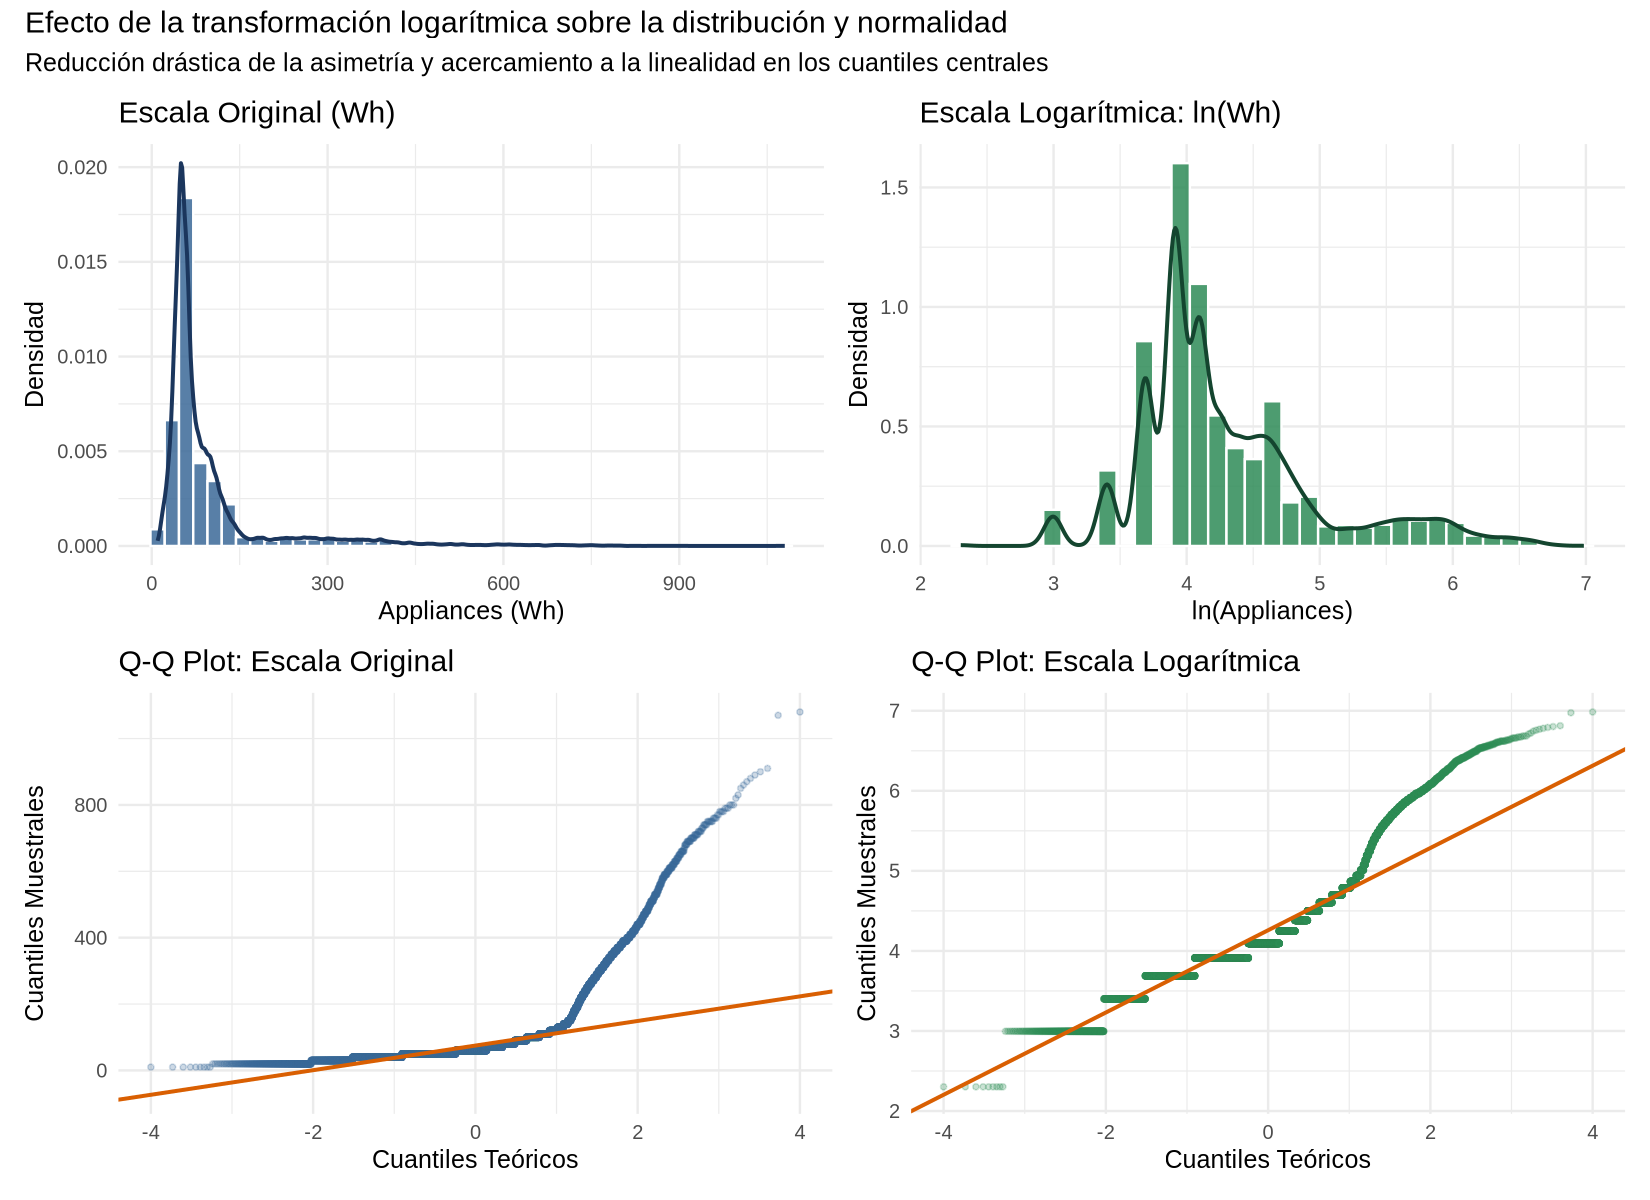

In [6]:
options(repr.plot.width = 11, repr.plot.height = 8, repr.plot.res = 150)

p1 <- ggplot(train_df, aes(x = Appliances)) +
  geom_histogram(aes(y = after_stat(density)), bins = 45, fill = "#3B6998", color = "white", alpha = 0.85) +
  geom_density(color = "#1B365D", linewidth = 0.9) +
  labs(title = "Escala Original (Wh)", x = "Appliances (Wh)", y = "Densidad")

p2 <- ggplot(train_df, aes(x = log_Appliances)) +
  geom_histogram(aes(y = after_stat(density)), bins = 35, fill = "#2E8B57", color = "white", alpha = 0.85) +
  geom_density(color = "#14452F", linewidth = 0.9) +
  labs(title = "Escala Logarítmica: ln(Wh)", x = "ln(Appliances)", y = "Densidad")

p3 <- ggplot(train_df, aes(sample = Appliances)) +
  stat_qq(alpha = 0.25, color = "#3B6998", size = 1) +
  stat_qq_line(color = "#D95F02", linewidth = 0.9) +
  labs(title = "Q-Q Plot: Escala Original", x = "Cuantiles Teóricos", y = "Cuantiles Muestrales")

p4 <- ggplot(train_df, aes(sample = log_Appliances)) +
  stat_qq(alpha = 0.25, color = "#2E8B57", size = 1) +
  stat_qq_line(color = "#D95F02", linewidth = 0.9) +
  labs(title = "Q-Q Plot: Escala Logarítmica", x = "Cuantiles Teóricos", y = "Cuantiles Muestrales")

(p1 | p2) / (p3 | p4) +
  plot_annotation(
    title = "Efecto de la transformación logarítmica sobre la distribución y normalidad",
    subtitle = "Reducción drástica de la asimetría y acercamiento a la linealidad en los cuantiles centrales"
  )

*Observaciones:*
- Los gráficos Q-Q (Quantile-Quantile) compara los valores de las distribuciones de consumo frente a una distribución normal teórica.
- Escala Original: El primer cuatil difiere porque el consumo no puede ser negativo. A partir del cuantil teórico +1 las curvas difiere en gran medida por los eventos de alto consumo.
- Escala Logarítmica: Los picos de alto consumo aun no logran ajustarse a la perfección lo que explica la asimetría, pero se logra disminuir la varianza en gran medida.
- Los escalones se deben a la precisión de los sensores, es posible que midan en múltiplos de 10 Wh y por eso se ven los escalones entre los valores 2 y 5. ($\ln(10) \approx 2,30$, $\ln(50) \approx 3,91$, $\ln(60) \approx 4,09$, etc.)

## 4. Comportamiento del consumo según la hora del día
Para evaluar cómo varía el consumo energético a lo largo del ciclo diario sin perder la granularidad de los registros cada 10 minutos, analizamos la distribución completa de `ln(Appliances)` en cada una de las 24 horas del día (0 a 23), superponiendo la trayectoria de la media horaria. 

El objetivo es:
1. Evaluar si es conveniente mantener las **24 categorías horarias** o agruparlas en **franjas horarias**.
2. Verificar si el patrón horario difiere entre **días de semana y fines de semana**.

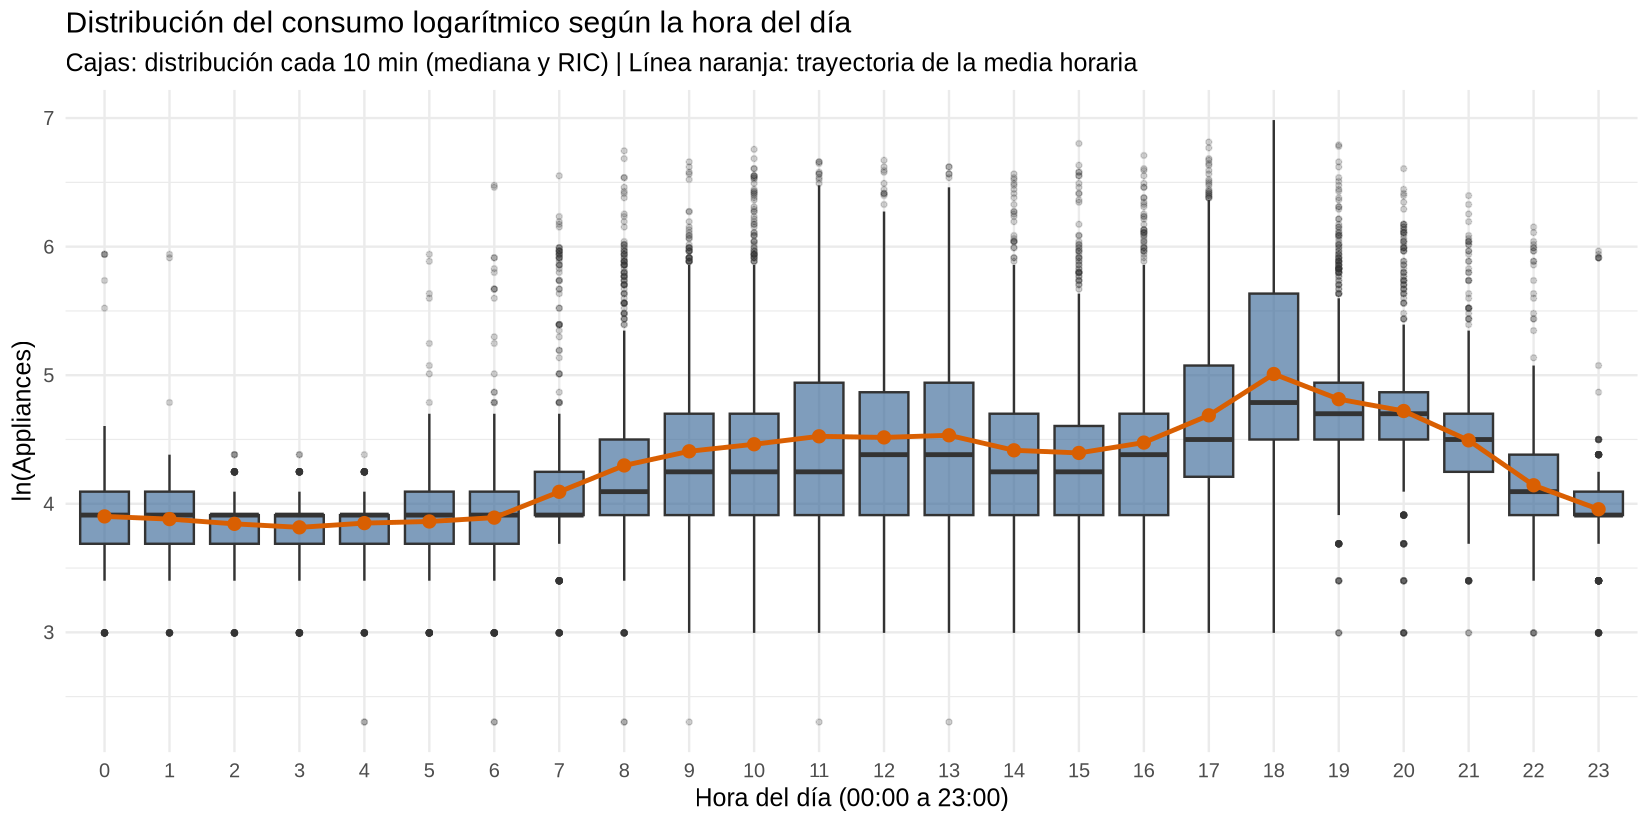

In [7]:
options(repr.plot.width = 11, repr.plot.height = 5.5, repr.plot.res = 150)

# Calcular resumen horario para superponer la curva de medias
resumen_hora <- train_df %>%
  group_by(hora) %>%
  summarise(
    media_log   = mean(log_Appliances),
    mediana_log = median(log_Appliances),
    .groups = "drop"
  )

ggplot(train_df, aes(x = hora, y = log_Appliances)) +
  geom_boxplot(fill = "#3B6998", alpha = 0.65, outlier.alpha = 0.2, outlier.size = 1) +
  geom_line(data = resumen_hora, aes(x = as.numeric(hora), y = media_log, group = 1),
            color = "#D95F02", linewidth = 1.1) +
  geom_point(data = resumen_hora, aes(x = as.numeric(hora), y = media_log),
             color = "#D95F02", size = 2.5) +
  labs(
    title = "Distribución del consumo logarítmico según la hora del día",
    subtitle = "Cajas: distribución cada 10 min (mediana y RIC) | Línea naranja: trayectoria de la media horaria",
    x = "Hora del día (00:00 a 23:00)",
    y = "ln(Appliances)"
  )

*Observaciones*:
- Existe un valle entre las 00 horas a hasta las 06 horas, con media $<4$ ($\approx 50$ Wh)
- Entre las 07 y 08 horas hay una fase de transición
- Entre las 09 y 16 el consumo es relativamente constante, con poca variabilidad: Su primer cuartil permance constante.
- Hay un pico significativo entre las 17 y 21 horas.
- Descenso del consumo entre las 22 y 23 horas.

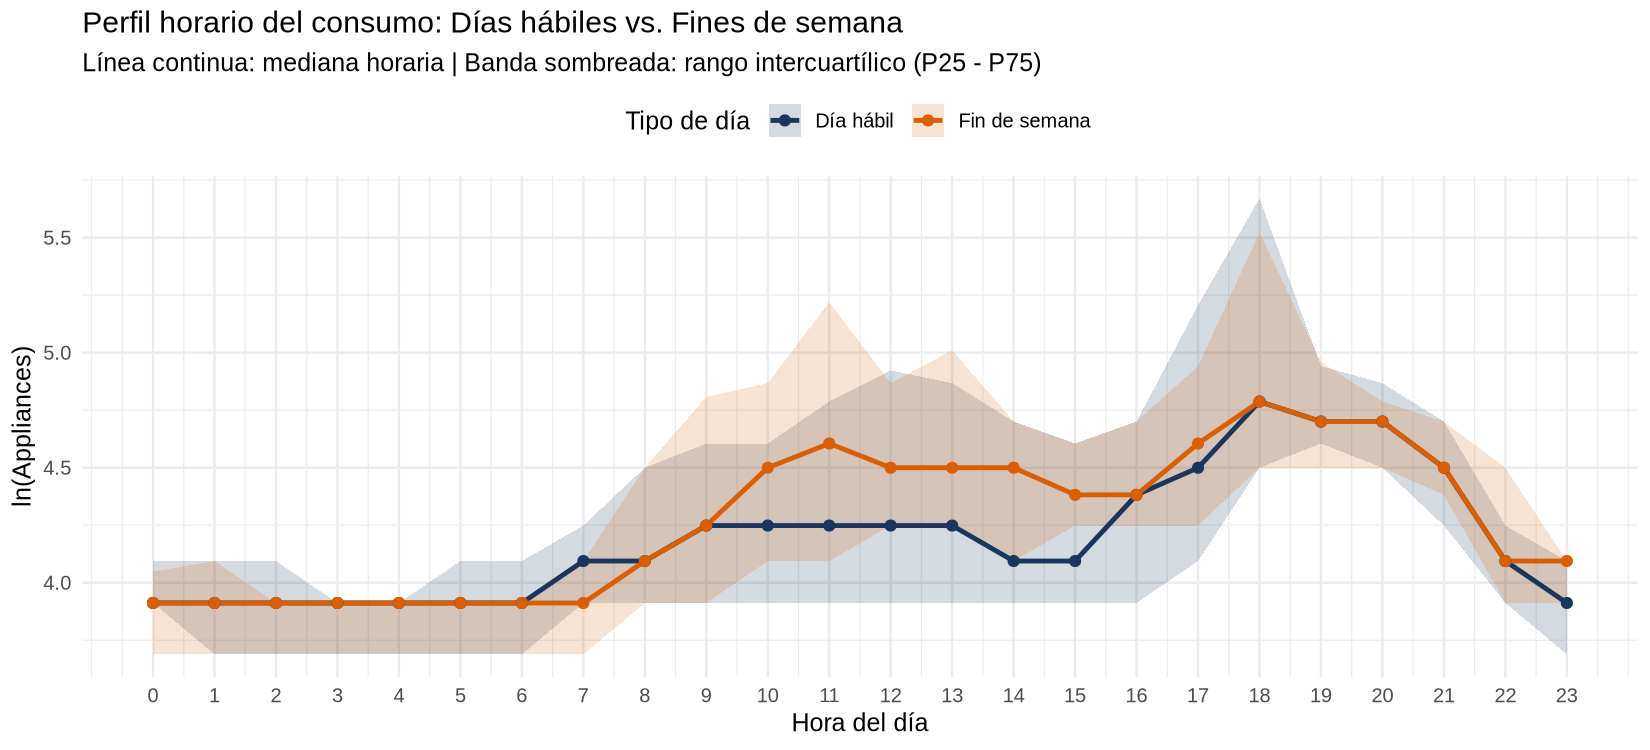

In [8]:
options(repr.plot.width = 11, repr.plot.height = 5, repr.plot.res = 150)

train_df <- train_df %>%
  mutate(
    dia_semana = lubridate::wday(date, week_start = 1), # 1 = Lunes, 7 = Domingo
    tipo_dia   = if_else(dia_semana %in% c(6, 7), "Fin de semana", "Día hábil")
  )

perfil_tipo_dia <- train_df %>%
  group_by(tipo_dia, hora) %>%
  summarise(
    mediana = median(log_Appliances),
    p25     = quantile(log_Appliances, 0.25),
    p75     = quantile(log_Appliances, 0.75),
    media   = mean(log_Appliances),
    .groups = "drop"
  )

ggplot(perfil_tipo_dia, aes(x = as.numeric(as.character(hora)), y = mediana, color = tipo_dia, fill = tipo_dia)) +
  geom_ribbon(aes(ymin = p25, ymax = p75), alpha = 0.18, color = NA) +
  geom_line(linewidth = 1.1) +
  geom_point(size = 2) +
  scale_x_continuous(breaks = 0:23) +
  scale_color_manual(values = c("Día hábil" = "#1B365D", "Fin de semana" = "#D95F02")) +
  scale_fill_manual(values = c("Día hábil" = "#1B365D", "Fin de semana" = "#D95F02")) +
  labs(
    title = "Perfil horario del consumo: Días hábiles vs. Fines de semana",
    subtitle = "Línea continua: mediana horaria | Banda sombreada: rango intercuartílico (P25 - P75)",
    x = "Hora del día",
    y = "ln(Appliances)",
    color = "Tipo de día",
    fill  = "Tipo de día"
  ) +
  theme(legend.position = "top")

*Observación*: Existe un comportamiento similar entre días hábiles y fines de semana. Sin emgargo la meseta diuna es más alta con un pico presente a las 11 horas.

### Agrupación en franjas horarias homogéneas
A partir del perfil descrito anteriormente se describen la siguiente franja horaria:

* **Madrugada (00–06):** Consumo base mínimo y estabilidad máxima.
* **Mañana (07–08):** Repunte inicial de actividad.
* **Día (09–16):** Meseta diurna de consumo intermedio.
* **Pico Vespertino (17–21):** Máxima demanda energética del hogar.
* **Noche (22–23):** Transición de descenso hacia el reposo.

In [9]:
# Crear factor ordenado cronológicamente
train_df <- train_df %>%
  mutate(
    hora_num = as.numeric(as.character(hora)),
    franja_horaria = case_when(
      hora_num >= 0  & hora_num <= 6  ~ "1. Madrugada\n(00-06)",
      hora_num >= 7  & hora_num <= 8  ~ "2. Mañana\n(07-08)",
      hora_num >= 9  & hora_num <= 16 ~ "3. Día\n(09-16)",
      hora_num >= 17 & hora_num <= 21 ~ "4. Pico Vespertino\n(17-21)",
      hora_num >= 22 & hora_num <= 23 ~ "5. Noche\n(22-23)"
    ),
    franja_horaria = factor(franja_horaria)
  )

# Resumen numérico por franja para respaldar la separación
resumen_franja <- train_df %>%
  group_by(franja_horaria) %>%
  summarise(
    Observaciones = n(),
    Mediana_log   = round(median(log_Appliances), 3),
    Media_log     = round(mean(log_Appliances), 3),
    RIC_log       = round(IQR(log_Appliances), 3),
    Desv_Est_log  = round(sd(log_Appliances), 3),
    Mediana_Wh    = round(median(Appliances), 1),
    Media_Wh      = round(mean(Appliances), 1),
    .groups = "drop"
  )

resumen_franja

franja_horaria,Observaciones,Mediana_log,Media_log,RIC_log,Desv_Est_log,Mediana_Wh,Media_Wh
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1. Madrugada (00-06),4620,3.912,3.864,0.405,0.314,50,50.4
2. Mañana (07-08),1316,4.094,4.195,0.370,0.652,60,88.5
3. Día (09-16),5232,4.248,4.466,0.788,0.734,70,120.2
4. Pico Vespertino (17-21),3300,4.605,4.745,0.560,0.654,100,146.9
5. Noche (22-23),1320,4.094,4.051,0.336,0.403,60,63.8


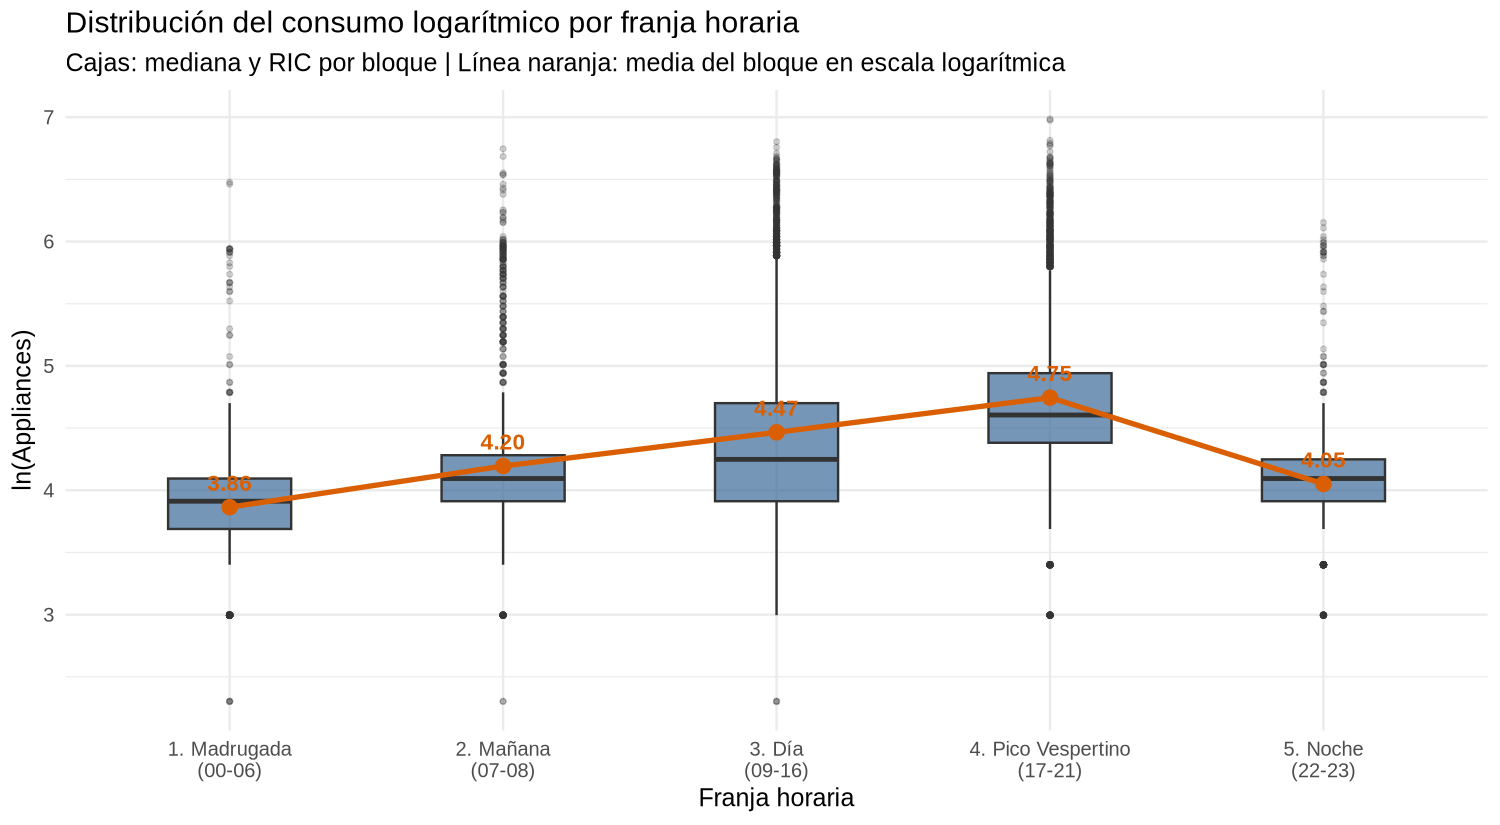

In [10]:
options(repr.plot.width = 10, repr.plot.height = 5.5, repr.plot.res = 150)

ggplot(train_df, aes(x = franja_horaria, y = log_Appliances)) +
  geom_boxplot(fill = "#3B6998", alpha = 0.7, width = 0.45, outlier.alpha = 0.2, outlier.size = 1) +
  geom_line(data = resumen_franja, aes(x = as.numeric(franja_horaria), y = Media_log, group = 1),
            color = "#D95F02", linewidth = 1.2) +
  geom_point(data = resumen_franja, aes(x = as.numeric(franja_horaria), y = Media_log),
             color = "#D95F02", size = 3) +
  geom_text(data = resumen_franja, aes(x = as.numeric(franja_horaria), y = Media_log,
                                       label = sprintf("%.2f", Media_log)),
            vjust = -1.1, color = "#D95F02", fontface = "bold", size = 3.8) +
  labs(
    title = "Distribución del consumo logarítmico por franja horaria",
    subtitle = "Cajas: mediana y RIC por bloque | Línea naranja: media del bloque en escala logarítmica",
    x = "Franja horaria",
    y = "ln(Appliances)"
  )

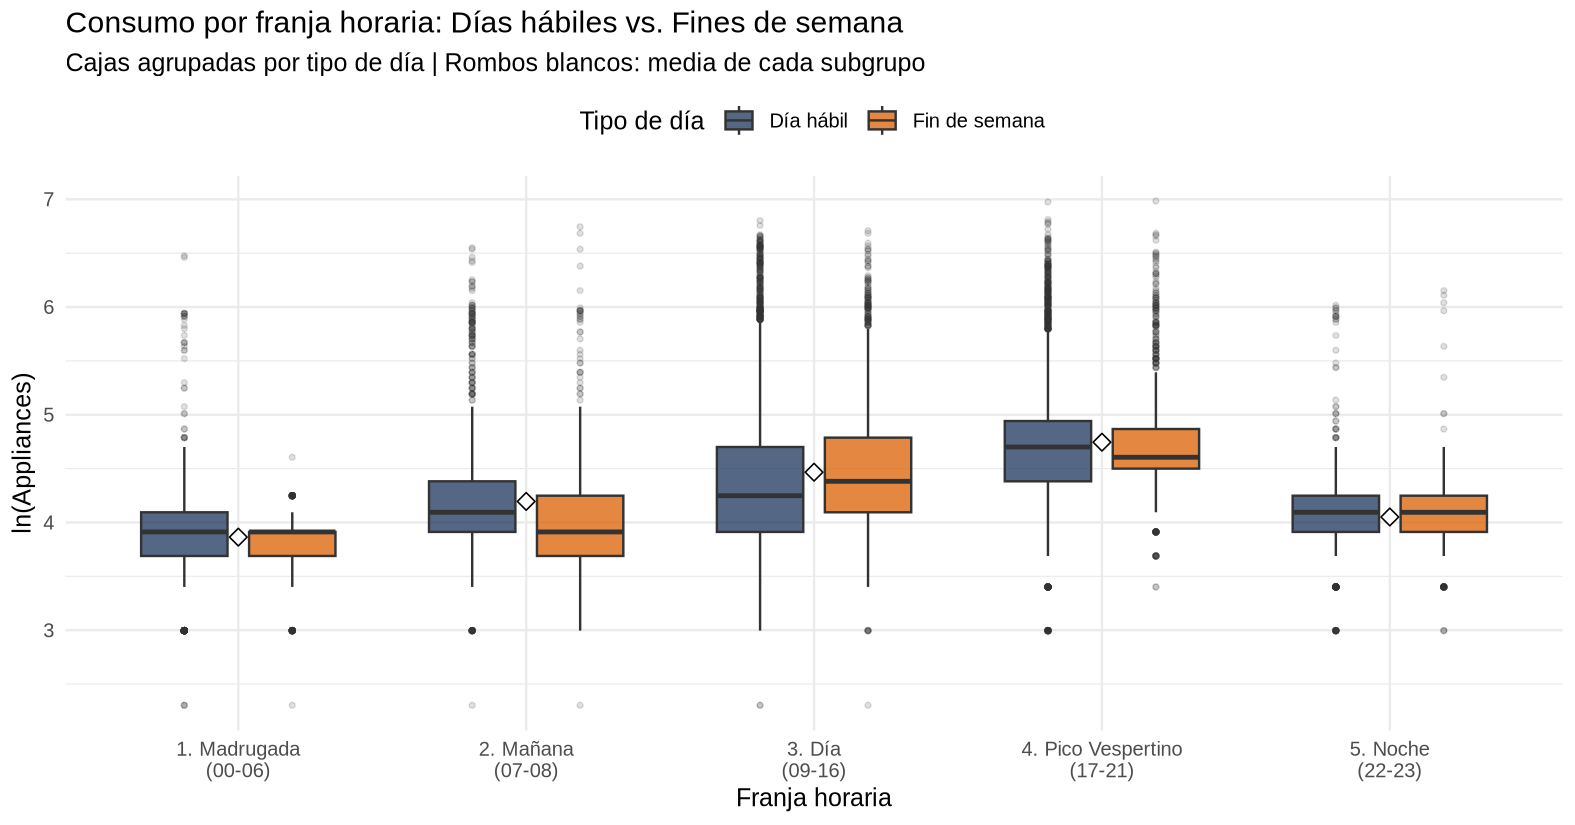

In [11]:
options(repr.plot.width = 10.5, repr.plot.height = 5.5, repr.plot.res = 150)

# Calcular medias por franja y tipo de día para superponer puntos
medias_franja_dia <- train_df %>%
  group_by(franja_horaria, tipo_dia) %>%
  summarise(media_log = mean(log_Appliances), .groups = "drop")

ggplot(train_df, aes(x = franja_horaria, y = log_Appliances, fill = tipo_dia)) +
  geom_boxplot(alpha = 0.75, position = position_dodge(width = 0.75),
               width = 0.6, outlier.alpha = 0.15, outlier.size = 1) +
  stat_summary(fun = mean, geom = "point", shape = 23, size = 2.8, fill = "white",
               position = position_dodge(width = 0.75)) +
  scale_fill_manual(values = c("Día hábil" = "#1B365D", "Fin de semana" = "#D95F02")) +
  labs(
    title = "Consumo por franja horaria: Días hábiles vs. Fines de semana",
    subtitle = "Cajas agrupadas por tipo de día | Rombos blancos: media de cada subgrupo",
    x = "Franja horaria",
    y = "ln(Appliances)",
    fill = "Tipo de día"
  ) +
  theme(legend.position = "top")

*Observación*: La diferencia vista en la franja de `día` no era realmente tan significativo.

## 5. Relaciones marginales entre consumo, temperatura y humedad
Para explorar de forma visual cómo se asocian las condiciones ambientales con `ln(Appliances)`, seleccionamos cuatro zonas representativas: 
- Cocina (`T1`, `RH_1`)
- Sala de estar (`T2`, `RH_2`)
- Dormitorio principal (`T9`, `RH_9`)
- Exterior (`To`, `RH_out`)

En cada panel superponemos una tendencia lineal (azul) y una curva suavizada (naranja) sobre la nube de observaciones para evaluar la dirección general y verificar si existen curvaturas pronunciadas.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


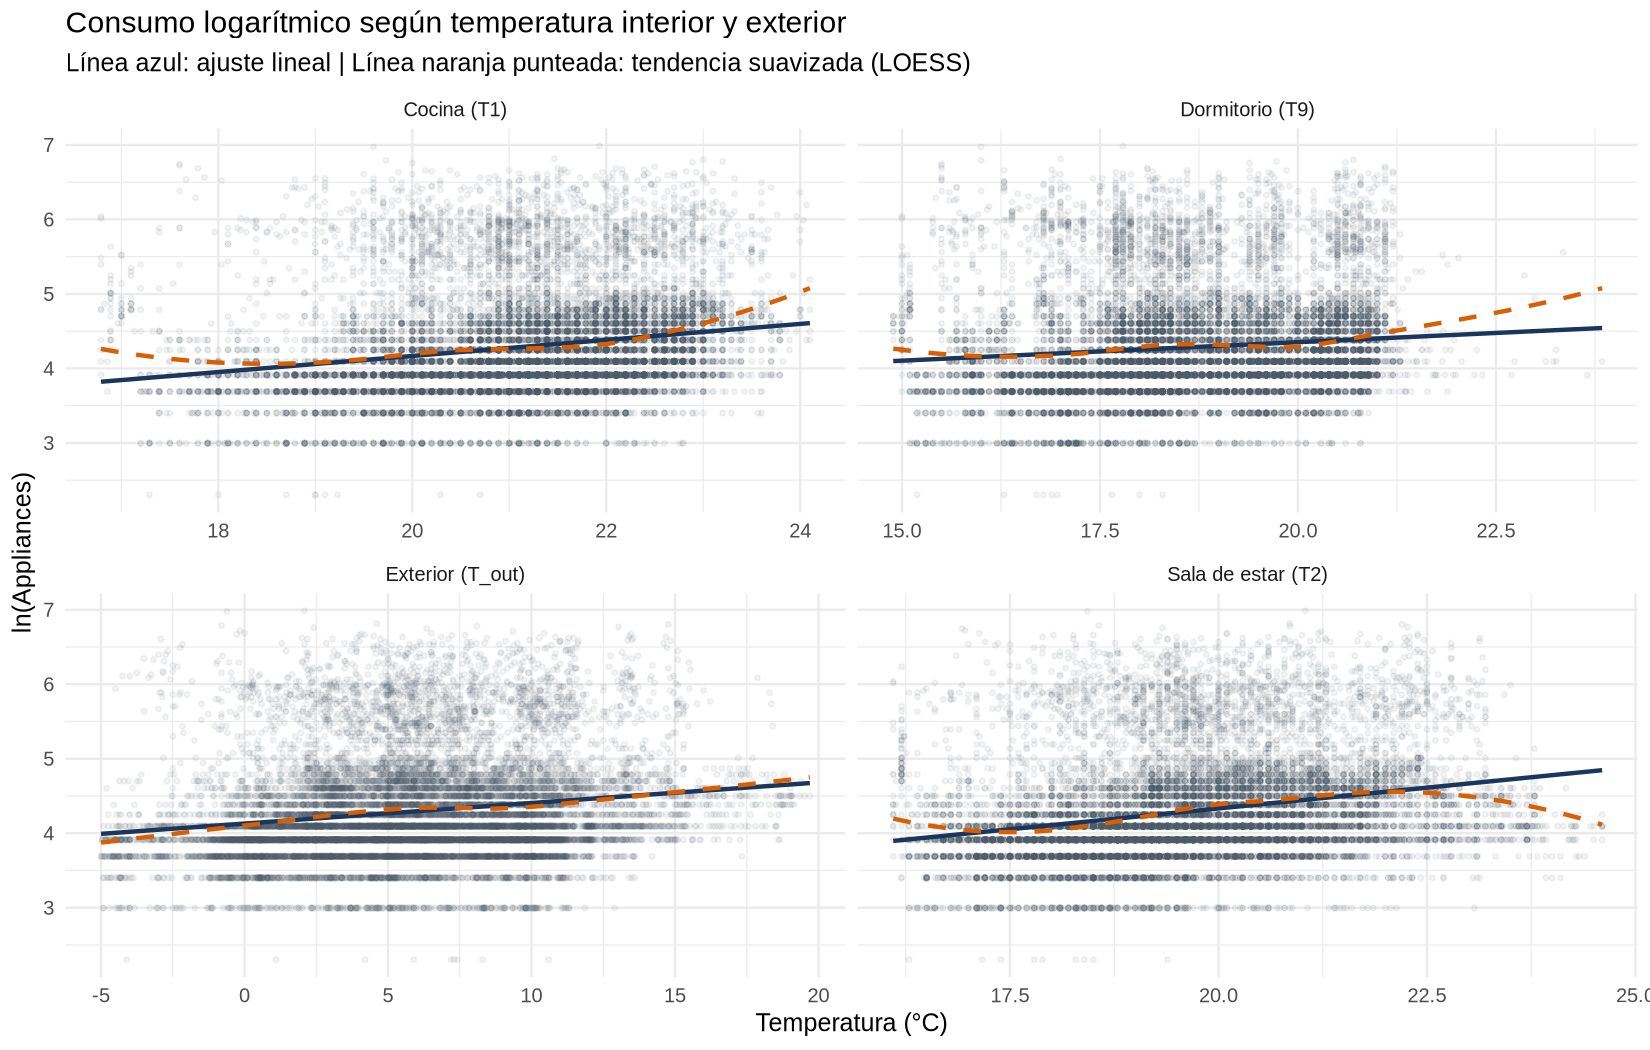

In [12]:
options(repr.plot.width = 11, repr.plot.height = 7, repr.plot.res = 150)

# Reestructurar temperaturas seleccionadas a formato largo para graficar en paneles
temp_long <- train_df %>%
  select(log_Appliances, T1, T2, T9, T_out) %>%
  pivot_longer(cols = -log_Appliances, names_to = "Zona", values_to = "Temperatura") %>%
  mutate(Zona = recode(Zona,
    "T1" = "Cocina (T1)",
    "T2" = "Sala de estar (T2)",
    "T9" = "Dormitorio (T9)",
    "T_out" = "Exterior (T_out)"
  ))

ggplot(temp_long, aes(x = Temperatura, y = log_Appliances)) +
  geom_point(alpha = 0.07, color = "#4A5568", size = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "#1B365D", linewidth = 1) +
  geom_smooth(method = "loess", se = FALSE, color = "#D95F02", linetype = "dashed", linewidth = 1) +
  facet_wrap(~ Zona, scales = "free_x", ncol = 2) +
  labs(
    title = "Consumo logarítmico según temperatura interior y exterior",
    subtitle = "Línea azul: ajuste lineal | Línea naranja punteada: tendencia suavizada (LOESS)",
    x = "Temperatura (°C)",
    y = "ln(Appliances)"
  )

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


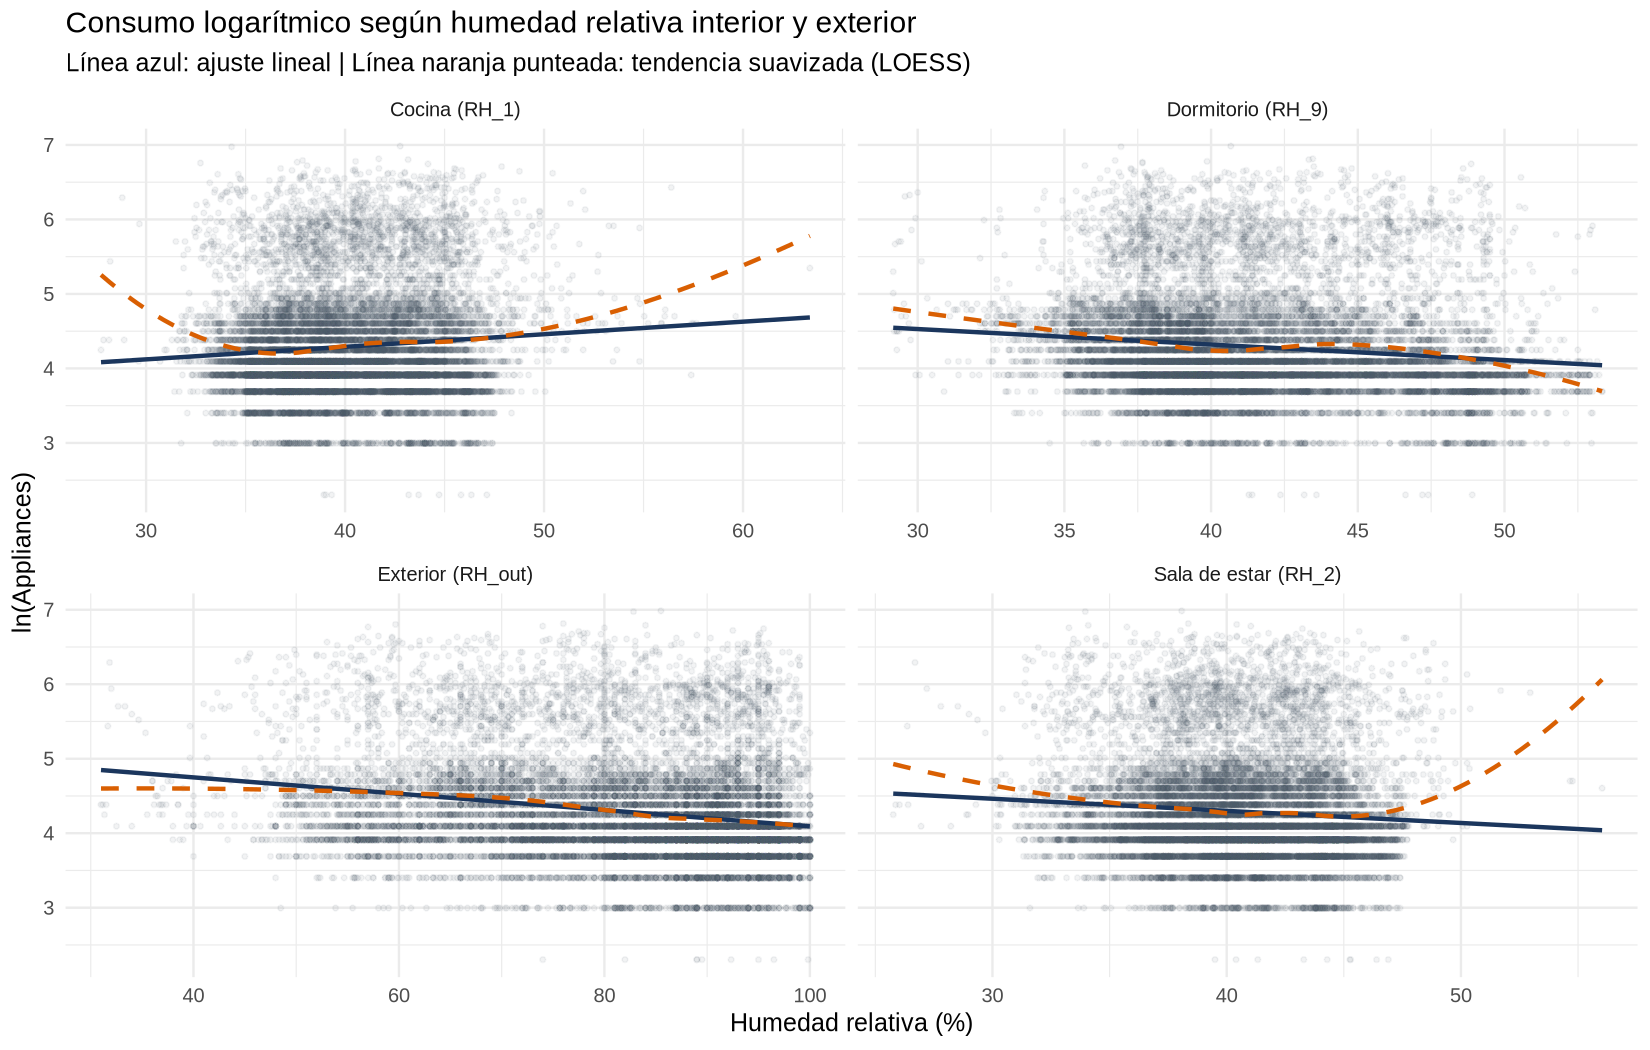

In [13]:
options(repr.plot.width = 11, repr.plot.height = 7, repr.plot.res = 150)

hum_long <- train_df %>%
  select(log_Appliances, RH_1, RH_2, RH_9, RH_out) %>%
  pivot_longer(cols = -log_Appliances, names_to = "Zona", values_to = "Humedad") %>%
  mutate(Zona = recode(Zona,
    "RH_1"   = "Cocina (RH_1)",
    "RH_2"   = "Sala de estar (RH_2)",
    "RH_9"   = "Dormitorio (RH_9)",
    "RH_out" = "Exterior (RH_out)"
  ))

ggplot(hum_long, aes(x = Humedad, y = log_Appliances)) +
  geom_point(alpha = 0.07, color = "#4A5568", size = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "#1B365D", linewidth = 1) +
  geom_smooth(method = "loess", se = FALSE, color = "#D95F02", linetype = "dashed", linewidth = 1) +
  facet_wrap(~ Zona, scales = "free_x", ncol = 2) +
  labs(
    title = "Consumo logarítmico según humedad relativa interior y exterior",
    subtitle = "Línea azul: ajuste lineal | Línea naranja punteada: tendencia suavizada (LOESS)",
    x = "Humedad relativa (%)",
    y = "ln(Appliances)"
  )

*Observaciones*:
- Las tendencias al alta y la baja, tanto en temperatuta como humedad se ven acompañadas de aumento y diminución de consumo respectivamente. Sobretodo en el cuerpo principal de los datos (la mayoría de las observaciones).
- Desvío en los extremos: La baja densidad en las zonas extremas hace que las curvas difieran. La tendencia suavizada ajusta localmente en esas zonas, pocos eventos muestran una imagen diferente que no es tan confiable como las observaciones centrales.
- Distinas zonas de la casa muestran comportamientos diferentes. Por ejemplo: Cocina vs Dormitorio.

## 6. Resumen

En esta etapa de exploración de datos, analizamos el comportamiento del consumo energético de los electrodomésticos (Appliances) respetando estrictamente el orden cronológico mediante una división del 80 % inicial para entrenamiento y 20 % final para validación, evitando así cualquier filtración de información futura. Los resultados muestran que el gasto eléctrico de la vivienda se mantiene mayormente en un consumo base bajo y estable (con una mediana de 60 Wh), pero se ve interrumpido por picos intensos y breves asociados al uso de equipos de alta potencia (que elevan el promedio a 98 Wh y alcanzan máximos de 1080 Wh), generando una fuerte asimetría hacia la derecha. Para corregir este desbalance y estabilizar la variabilidad de los datos de cara al modelamiento, evaluamos una transformación logarítmica sobre la variable de consumo; esta logró reducir en un 90 % el peso de los valores extremos (curtosis) y acercar significativamente los datos a una distribución normal, aunque persiste una ligera asimetría propia de los distintos hábitos de uso según la hora del día.